# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

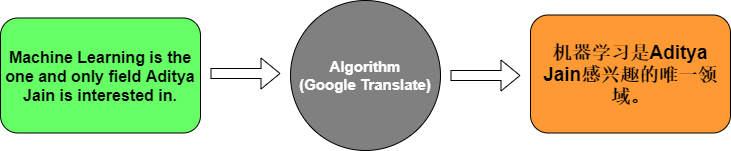

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [3]:
%pip install tensorflow

  Using cached tensorflow-2.21.0-cp311-cp311-win_amd64.whl.metadata (4.5 kB)
  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-py2.py3-none-win_amd64.whl.metadata (5.3 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached grpcio-1.85.0-cp311-cp311-win_amd64.whl.metadata (3.9 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached h5py-3.14.0-cp311-cp311-win_amd64.whl.metadata (2.7 kB)
  Using cached ml_dtypes-0.6.0-cp311-cp311-win_amd64.whl.metadata (8.8 kB)
  Using cach

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


   ---------------------------------------- 0.0/350.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/350.8 MB ? eta -:--:--
   ---------------------------------------- 0.3/350.8 MB ? eta -:--:--
   ---------------------------------------- 0.5/350.8 MB 1.5 MB/s eta 0:03:49
   ---------------------------------------- 1.0/350.8 MB 2.0 MB/s eta 0:02:54
   ---------------------------------------- 1.6/350.8 MB 2.0 MB/s eta 0:02:51
   ---------------------------------------- 2.1/350.8 MB 2.1 MB/s eta 0:02:50
   ---------------------------------------- 2.4/350.8 MB 2.0 MB/s eta 0:02:57
   ---------------------------------------- 2.6/350.8 MB 1.9 MB/s eta 0:03:03
   ---------------------------------------- 2.9/350.8 MB 1.9 MB/s eta 0:03:05
   ---------------------------------------- 3.4/350.8 MB 1.8 MB/s eta 0:03:12
   ---------------------------------------- 3.9/350.8 MB 1.9 MB/s eta 0:03:02
   ---------------------------------------- 4.2/350.8 MB 2.0 MB/s eta 0:02:58
    ---

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [6]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [7]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [8]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.usercontent.google.com/download?id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI&export=view&authuser=0" width="550">

In [10]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 0.1429 - loss: 2.4836 - val_accuracy: 0.0000e+00 - val_loss: 2.4869
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.5714 - loss: 2.4756 - val_accuracy: 0.0000e+00 - val_loss: 2.4892
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.5714 - loss: 2.4674 - val_accuracy: 0.0000e+00 - val_loss: 2.4917
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.5714 - loss: 2.4584 - val_accuracy: 0.0000e+00 - val_loss: 2.4945
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4485 - val_accuracy: 0.0000e+00 - val_loss: 2.4976
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5714 - loss: 2.4372 - val_accuracy: 0.0000e+00 - val_loss: 2.5012
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step - accuracy: 0.5714 - loss: 2.4242 - val_accuracy: 0.0000e+00 - val_loss: 2.5053
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5714 - loss: 2.4091 - val_accuracy: 

In [11]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers**

**1.** It turns the word index into a vector of numbers that represents the word's meaning.

**2.** It reads the English sentence and summarizes it into one vector.

**3.** It takes that summary and generates the French sentence word by word.

**4.** To turn the outputs into probabilities, so we can pick the most likely word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [13]:
%pip install kagglehub


  Attempting uninstall: certifi

    Found existing installation: certifi 2026.7.22

    Uninstalling certifi-2026.7.22:

      Successfully uninstalled certifi-2026.7.22

   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   ------------- -------------------------- 1/3 [kagglesdk]
   -------------------------- ------------- 2/3 [kagglehub]
   ---------------------------------------- 3/3 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


In [14]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")

print("Path to dataset files:", path)

100%|██████████| 3.51M/3.51M [00:00<00:00, 4.00MB/s]

Extracting files...
Path to dataset files: C:\Users\rvl19\.cache\kagglehub\datasets\devicharith\language-translation-englishfrench\versions\2


In [16]:
# Remove empty rows and duplicate rows
df = df.dropna().drop_duplicates()

# Keep only short sentences (10 words or less) to make training faster
df = df[df["english"].str.split().str.len() <= 10]
df = df[df["french"].str.split().str.len() <= 10]

# Take a random sample of 20,000 sentence pairs
df = df.sample(n=20000, random_state=42).reset_index(drop=True)

english_sentences = df["english"].tolist()
french_sentences = df["french"].tolist()

In [17]:
# Tokenize English sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences)
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences)

# Tokenize French sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

# Vocabulary sizes (+1 because index 0 is reserved for padding)
eng_vocab_size = len(tokenizer_eng.word_index) + 1
frn_vocab_size = len(tokenizer_frn.word_index) + 1

print("English vocabulary size:", eng_vocab_size)
print("French vocabulary size:", frn_vocab_size)

English vocabulary size: 5977
French vocabulary size: 10591


In [18]:
# Find the longest sentence in each language
max_eng_len = max(len(s) for s in eng_sequences)
max_frn_len = max(len(s) for s in frn_sequences)

# English: zeros at the beginning (default)
eng_padded = pad_sequences(eng_sequences, maxlen=max_eng_len)

# French: zeros at the end, so the translation starts from the first position
frn_padded = pad_sequences(frn_sequences, maxlen=max_frn_len, padding='post')

print("English shape:", eng_padded.shape)
print("French shape:", frn_padded.shape)

English shape: (20000, 11)
French shape: (20000, 12)


In [19]:
# 80% for training, 20% for testing
eng_train, eng_test, frn_train, frn_test = train_test_split(
    eng_padded, frn_padded, test_size=0.2, random_state=42
)

In [20]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(max_eng_len,)),
    tf.keras.layers.Embedding(input_dim=eng_vocab_size, output_dim=128),
    tf.keras.layers.LSTM(256),                                   # Encoder
    tf.keras.layers.RepeatVector(max_frn_len),                   # Repeat summary for each French word
    tf.keras.layers.LSTM(256, return_sequences=True),            # Decoder
    tf.keras.layers.TimeDistributed(
        tf.keras.layers.Dense(frn_vocab_size, activation='softmax')
    )
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 11, 128)        │       765,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 256)            │       394,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ repeat_vector_2 (RepeatVector)  │ (None, 12, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 12, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed_2              │ (None, 12, 10591)      │     2,721,887 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,406,495 (16.81 MB)

 Trainable params: 4,406,495 (16.81 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
history = model.fit(
    eng_train,
    np.expand_dims(frn_train, -1),
    epochs=20,
    batch_size=64,
    validation_split=0.1
)

Epoch 1/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 34s 143ms/step - accuracy: 0.4924 - loss: 4.2103 - val_accuracy: 0.5144 - val_loss: 3.7297
Epoch 2/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 1830s 8s/step - accuracy: 0.5105 - loss: 3.6327 - val_accuracy: 0.5185 - val_loss: 3.6355
Epoch 3/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 34s 153ms/step - accuracy: 0.5153 - loss: 3.5469 - val_accuracy: 0.5217 - val_loss: 3.6208
Epoch 4/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 33s 149ms/step - accuracy: 0.5181 - loss: 3.4922 - val_accuracy: 0.5222 - val_loss: 3.5861
Epoch 5/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 30s 132ms/step - accuracy: 0.5195 - loss: 3.4510 - val_accuracy: 0.5227 - val_loss: 3.5658
Epoch 6/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 31s 136ms/step - accuracy: 0.5199 - loss: 3.4164 - val_accuracy: 0.5226 - val_loss: 3.5543
Epoch 7/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 30s 135ms/step - accuracy: 0.5202 - loss: 3.3890 - val_accuracy: 0.5230 - val_loss: 3.5372
Epoch 8/20
225/225 ━━━━━━━━━━━━━━━━━━━━ 30s 134ms/step - accuracy: 0.5228 - loss: 3.

In [22]:
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f"Test Accuracy: {accuracy:.4f}")

125/125 ━━━━━━━━━━━━━━━━━━━━ 3s 24ms/step - accuracy: 0.5501 - loss: 3.1895
Test Accuracy: 0.5501


In [23]:
def translate_sentence(sentence):
    sequence = tokenizer_eng.texts_to_sequences([sentence])
    padded = pad_sequences(sequence, maxlen=max_eng_len)
    prediction = model.predict(padded, verbose=0)
    predicted_ids = np.argmax(prediction, axis=-1)
    return tokenizer_frn.sequences_to_texts(predicted_ids)[0]

# Try the model on 5 sentences from the test set
for i in range(5):
    eng_text = tokenizer_eng.sequences_to_texts([eng_test[i]])[0]
    true_frn = tokenizer_frn.sequences_to_texts([frn_test[i]])[0]
    print("English:   ", eng_text)
    print("Actual:    ", true_frn)
    print("Predicted: ", translate_sentence(eng_text))
    print("-" * 40)

English:    you are completely wrong
Actual:     tu as complètement tort
Predicted:  vous vous le
----------------------------------------
English:    please write your date of birth here
Actual:     écris ta date de naissance ici s'il te plaît
Predicted:  j'ai vous vous à à à
----------------------------------------
English:    we want it back
Actual:     nous voulons la récupérer
Predicted:  nous vous vous
----------------------------------------
English:    why are you so secretive
Actual:     pourquoi êtes vous aussi secret
Predicted:  vous vous vous de
----------------------------------------
English:    i oiled my bicycle
Actual:     j'ai huilé mon vélo
Predicted:  je suis à de
----------------------------------------
